# AI for Business Analytics — Mini Project
## Smart Airbnb Pricing System
**Goal:** predict the nightly price of an Airbnb listing 

**Dataset:** Kaggle *Airbnb Price Prediction* (`train.csv`) 

**Main model:** Linear Regression 

### Project workflow
1. Import libraries and load the data
2. Understand the data and check its quality
3. Clean the data
4. Feature engineering (turn raw columns, especially `amenities`, into model-ready features)
5. Exploratory Data Analysis (EDA) and business insights
6. Select features, split into train / test
7. Build and train the models
8. Evaluate (MAE, RMSE, R²) and plot actual vs predicted
9. Explain the Linear Regression (what increases the price?)
10. Predict a price for a new listing, then save the model for a website

In [1]:
## 1. Import libraries

import pandas as pd
import numpy as np

# The real dataset is loaded in the next cell. Do not generate or overwrite train.csv here.
print("Libraries ready; the provided dataset will be loaded in the next section.")


Libraries ready; the provided dataset will be loaded in the next section.


In [2]:
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 100

In [3]:
# Load the provided dataset without overwriting it
from pathlib import Path

DATA_PATH = Path("train(1).csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("train.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Dataset not found. Keep train(1).csv (or train.csv) in the same folder as this notebook."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded dataset: {DATA_PATH.resolve()}")
print("Dataset shape:", df.shape)


Loaded dataset: /Users/anishmd/train.csv
Dataset shape: (100, 17)


## 3. Understand the dataset

* Each **row = one Airbnb listing**.
* The target column is **`log_price`** = the *natural logarithm* of the nightly price in US dollars.
  So the real price is `price = e^(log_price)`  (in code: `np.exp(log_price)`).
* Prices are *right-skewed* (a few very expensive listings), so the dataset authors stored the log.
  Models usually predict the log price better, and we convert back to dollars at the end.

In [4]:
print("Shape (rows, columns):", df.shape)

print("\nColumn types:")
display(df.dtypes.to_frame("type"))

print("\nMissing values (only columns that have some):")
missing = df.isna().sum()
display(missing[missing > 0].sort_values(ascending=False).to_frame("missing values"))

print("\nNumeric summary:")
display(df[["log_price", "accommodates", "bathrooms", "bedrooms", "beds"]].describe().round(2))

print("\nListings per city:")
display(df["city"].value_counts().to_frame("listings"))

print("\nListings per room type:")
display(df["room_type"].value_counts().to_frame("listings"))

Shape (rows, columns): (100, 17)

Column types:


,type
id,int64
log_price,float64
city,object
neighbourhood,object
property_type,object
room_type,object
bed_type,object
cancellation_policy,object
accommodates,int64
bathrooms,float64



Missing values (only columns that have some):


,missing values



Numeric summary:


,log_price,accommodates,bathrooms,bedrooms,beds
count,100.00,100.00,100.00,100.00,100.00
mean,5.47,4.79,1.72,2.50,2.89
std,0.58,2.54,0.58,1.04,1.32
min,3.95,1.00,1.00,1.00,1.00
25%,5.07,3.00,1.00,2.00,2.00
50%,5.55,5.00,1.50,3.00,3.00
75%,5.98,7.00,2.50,3.00,4.00
max,6.21,9.00,2.50,4.00,5.00



Listings per city:


,listings
city,
SF,28
NYC,22
Boston,17
Chicago,13
LA,13
DC,7



Listings per room type:


,listings
room_type,
Private room,37
Shared room,35
Entire home/apt,28


## 4. Data quality checks and cleaning

Checks and decisions:

1. **Duplicates:** remove exact duplicate rows (and duplicate listing `id`s).
2. **Invalid target:** `log_price = 0` means a price of $1 per night — not a real price, so those rows are removed.
3. **Create the real `price` column** in dollars from `log_price`.
4. **Expensive listings are kept.** Luxury homes are real; we do not delete them with an arbitrary cap.
   The log transformation already reduces their influence.
5. **Missing predictor values** (e.g. missing `bathrooms`) are filled *inside the model pipeline*,
   using only the training data. This avoids "data leakage" from the test set.

In [5]:
# Remove duplicate listing IDs and invalid target values
df_clean = df.drop_duplicates(subset=["id"]).copy()
df_clean["log_price"] = pd.to_numeric(df_clean["log_price"], errors="coerce")
df_clean = df_clean.replace([np.inf, -np.inf], np.nan)
df_clean = df_clean.dropna(subset=["log_price"])
df_clean = df_clean[df_clean["log_price"] > 0].copy()

# Convert log-price to US dollars
df_clean["price"] = np.exp(df_clean["log_price"])

if df_clean.empty:
    raise ValueError("No valid rows remain after cleaning. Check the log_price column.")

print(f"Total cleaned listings: {len(df_clean):,}")
print(f"Price range: ${df_clean['price'].min():,.0f} to ${df_clean['price'].max():,.0f} per night")


Total cleaned listings: 100
Price range: $52 to $497 per night


## 5. Feature engineering

Raw columns are not always ready for a model. Here we prepare them:

* **`amenities`** is one long text like `{"Wireless Internet","Kitchen",Heating,...}`.
  We turn the most important amenities into simple **0/1 columns** (1 = the listing has it).
* **`cleaning_fee`** (True/False) and **`instant_bookable`** (t/f) become 1/0.
* **`neighbourhood`** has missing values → we label them `"Unknown"`.

We do **not** use `id`, `name`, `description`, `thumbnail_url` or review columns:
they are identifiers/free text, and a *brand-new* listing has no reviews yet,
so a new-listing price estimator should not depend on them.

In [6]:
# Convert common amenities into binary features
AMENITY_MAP = {
    "has_wifi": "Wireless Internet",
    "has_kitchen": "Kitchen",
    "has_ac": "Air conditioning",
    "has_heating": "Heating",
    "has_tv": "TV",
    "has_parking": "parking",
}
AMENITY_FEATURES = list(AMENITY_MAP.keys())

amenity_text = df_clean["amenities"].fillna("").astype(str)
for col_name, pattern in AMENITY_MAP.items():
    df_clean[col_name] = amenity_text.str.contains(pattern, case=False, regex=False).astype(int)

def to_binary(series):
    return series.astype(str).str.strip().str.lower().isin(["true", "t", "1", "yes"]).astype(int)

df_clean["cleaning_fee"] = to_binary(df_clean["cleaning_fee"])
df_clean["instant_bookable"] = to_binary(df_clean["instant_bookable"])
df_clean["neighbourhood"] = df_clean["neighbourhood"].fillna("Unknown").astype(str)

display(df_clean[["amenities", *AMENITY_FEATURES, "cleaning_fee", "instant_bookable"]].head())


,amenities,has_wifi,has_kitchen,has_ac,has_heating,has_tv,has_parking,cleaning_fee,instant_bookable
0,"{""Wireless Internet"",""Kitchen"",""Air conditioni...",1,1,1,1,1,1,1,1
1,"{""Wireless Internet"",""Heating""}",1,0,0,1,0,0,0,0
2,"{""Wireless Internet"",""Kitchen"",""Air conditioni...",1,1,1,1,1,1,1,1
3,"{""Wireless Internet"",""Heating""}",1,0,0,1,0,0,1,0
4,"{""Wireless Internet"",""Kitchen"",""Air conditioni...",1,1,1,1,1,1,1,1


## 6. Exploratory Data Analysis (EDA)

EDA = looking at the data with charts before modelling. These charts can go straight into your report.
We use the **median** as well as the mean because a few luxury listings pull the mean upwards.

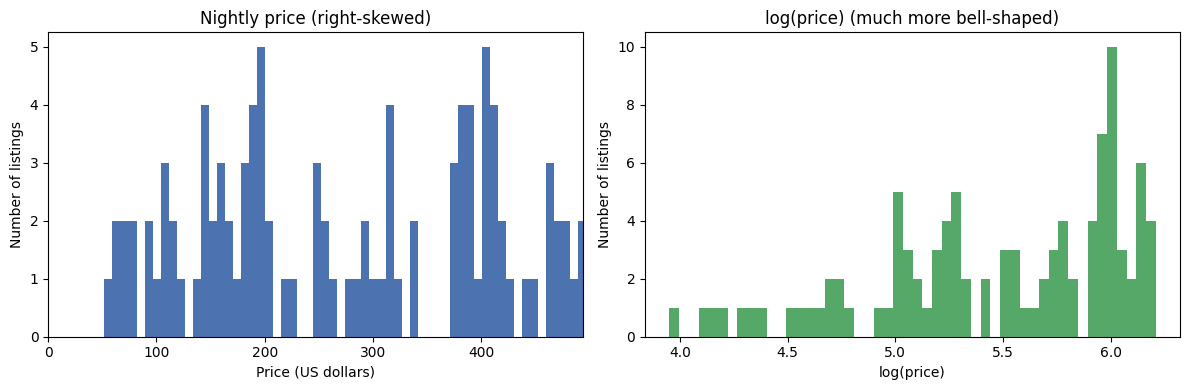

,median,mean,count
city,,,
DC,157.0,190.3,7
Boston,193.0,241.7,17
LA,255.0,281.9,13
SF,277.0,286.1,28
Chicago,290.0,270.4,13
NYC,348.0,304.8,22


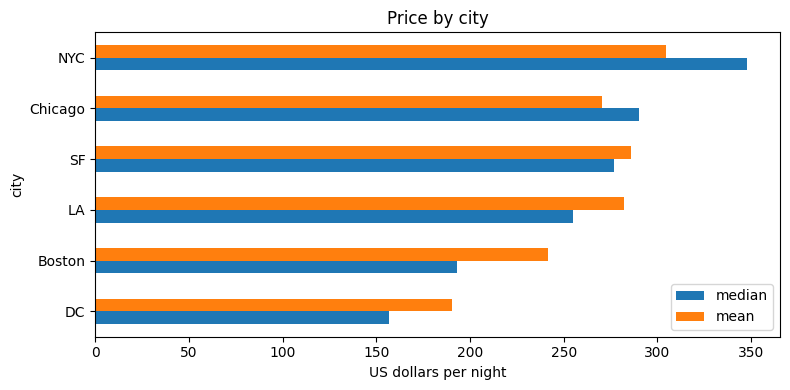

,median,mean,count
room_type,,,
Private room,251.0,274.7,37
Entire home/apt,260.5,277.6,28
Shared room,303.0,268.5,35


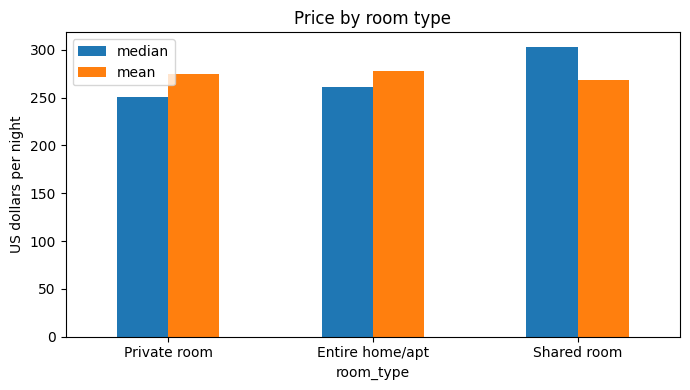

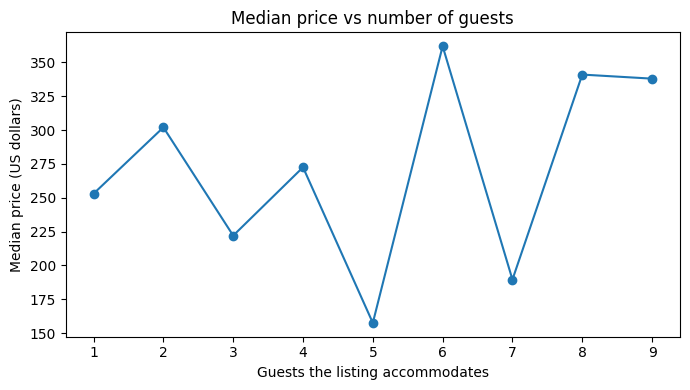

In [7]:
# ---- Chart 1: price distribution, normal vs log scale ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_clean["price"], bins=60, color="#4C72B0")
axes[0].set_xlim(0, df_clean["price"].quantile(0.99))   # zoom in for readability only
axes[0].set_title("Nightly price (right-skewed)")
axes[0].set_xlabel("Price (US dollars)"); axes[0].set_ylabel("Number of listings")

axes[1].hist(df_clean["log_price"], bins=50, color="#55A868")
axes[1].set_title("log(price) (much more bell-shaped)")
axes[1].set_xlabel("log(price)"); axes[1].set_ylabel("Number of listings")
plt.tight_layout(); plt.show()

# ---- Chart 2: price by city ----
city_summary = df_clean.groupby("city")["price"].agg(["median", "mean", "count"]).sort_values("median")
display(city_summary.round(1))
city_summary[["median", "mean"]].plot(kind="barh", figsize=(8, 4), title="Price by city")
plt.xlabel("US dollars per night"); plt.tight_layout(); plt.show()

# ---- Chart 3: price by room type ----
room_summary = df_clean.groupby("room_type")["price"].agg(["median", "mean", "count"]).sort_values("median")
display(room_summary.round(1))
room_summary[["median", "mean"]].plot(kind="bar", figsize=(7, 4), title="Price by room type")
plt.ylabel("US dollars per night"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

# ---- Chart 4: price vs number of guests ----
guest_summary = df_clean.groupby("accommodates")["price"].median()
guest_summary = guest_summary[guest_summary.index <= 10]
guest_summary.plot(kind="line", marker="o", figsize=(7, 4), title="Median price vs number of guests")
plt.xlabel("Guests the listing accommodates"); plt.ylabel("Median price (US dollars)")
plt.tight_layout(); plt.show()

## 7. Business analytics findings

The numbers below are computed from the data, so you can quote them in your report.
They show **differences and relationships** — they do not prove that one factor *causes* a price change.

In [8]:
top_city, low_city = city_summary["median"].idxmax(), city_summary["median"].idxmin()
top_room, low_room = room_summary["median"].idxmax(), room_summary["median"].idxmin()

print(f"Most expensive city (median): {top_city} (${city_summary.loc[top_city, 'median']:.0f}/night)")
print(f"Cheapest city (median)      : {low_city} (${city_summary.loc[low_city, 'median']:.0f}/night)")
print(f"Most expensive room type    : {top_room} (${room_summary.loc[top_room, 'median']:.0f}/night)")
print(f"Cheapest room type          : {low_room} (${room_summary.loc[low_room, 'median']:.0f}/night)")

rows = []
for col in AMENITY_FEATURES:
    with_it = df_clean.loc[df_clean[col] == 1, "price"].median()
    without = df_clean.loc[df_clean[col] == 0, "price"].median()
    rows.append({"amenity": AMENITY_MAP[col], "median price WITH": with_it, "median price WITHOUT": without})
display(pd.DataFrame(rows).round(1).set_index("amenity"))

print("\nBusiness interpretation: compare listings in the same city, room type, and similar size.")
print("These raw comparisons show associations, not proof of cause and effect.")


Most expensive city (median): NYC ($348/night)
Cheapest city (median)      : DC ($157/night)
Most expensive room type    : Shared room ($303/night)
Cheapest room type          : Private room ($251/night)


,median price WITH,median price WITHOUT
amenity,,
Wireless Internet,258.0,NaN
Kitchen,236.0,316.0
Air conditioning,236.0,316.0
Heating,258.0,NaN
TV,236.0,316.0
parking,236.0,316.0



Business interpretation: compare listings in the same city, room type, and similar size.
These raw comparisons show associations, not proof of cause and effect.


## 8. Select features (inputs) and target (output)

* **Target `y`:** `log_price` (we convert predictions back to dollars when evaluating).
* **Input features `X`**, all known by a host *before* the first booking:

| Type | Columns |
|---|---|
| Categories (text) | `city`, `neighbourhood`, `property_type`, `room_type`, `bed_type`, `cancellation_policy` |
| Numbers | `accommodates`, `bathrooms`, `bedrooms`, `beds`, `cleaning_fee`, `instant_bookable` + the amenity 0/1 columns |
| Extra for comparison model only | `latitude`, `longitude` (precise location; hard for a website user to type, so Linear Regression doesn't use them) |

In [9]:
# Define features and target
TARGET = "log_price"

CATEGORICAL_FEATURES = [
    "city", "neighbourhood", "property_type", "room_type", "bed_type", "cancellation_policy"
]
NUMERIC_FEATURES = [
    "accommodates", "bathrooms", "bedrooms", "beds", "cleaning_fee", "instant_bookable",
    *AMENITY_FEATURES
]
ALL_FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

X = df_clean[ALL_FEATURES].copy()
y = df_clean[TARGET].copy()

display(X.head())
print(f"Input columns: {len(ALL_FEATURES)}")


,city,neighbourhood,property_type,room_type,bed_type,cancellation_policy,accommodates,bathrooms,bedrooms,beds,cleaning_fee,instant_bookable,has_wifi,has_kitchen,has_ac,has_heating,has_tv,has_parking
0,DC,Unknown,Apartment,Shared room,Real Bed,moderate,1,1.0,4,5,1,1,1,1,1,1,1,1
1,DC,Unknown,Apartment,Entire home/apt,Real Bed,strict,1,2.0,3,2,0,0,1,0,0,1,0,0
2,SF,Hollywood,Apartment,Private room,Real Bed,flexible,7,2.0,1,5,1,1,1,1,1,1,1,1
3,Boston,Williamsburg,House,Shared room,Real Bed,strict,9,1.0,4,4,1,0,1,0,0,1,0,0
4,NYC,Hell's Kitchen,Apartment,Private room,Futon,flexible,2,2.5,4,1,1,1,1,1,1,1,1,1


Input columns: 18


## 9. Train / test split

* **80 % training data:** the model learns from these listings.
* **20 % test data:** hidden from the model during training; we use it at the end to check
  how well the model works on listings it has **never seen** (like a real exam).

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Training rows: {len(X_train):,}")
print(f"Testing rows : {len(X_test):,}")

Training rows: 80
Testing rows : 20


## 10. Build the models

A **pipeline** chains preprocessing and the model so the same steps are applied to training data, test data, and new listings.

We compare two models:
1. **Median baseline:** always predicts the median log-price in the training data.
2. **Linear Regression:** learns a weighted relationship between the encoded features and log-price.

Categorical values are imputed with the most frequent training value and one-hot encoded. Numeric missing values are imputed with the training median. Unknown categories are ignored safely during prediction.


In [11]:
# Preprocessing: impute missing values and one-hot encode categories
preprocessor = ColumnTransformer(transformers=[
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), CATEGORICAL_FEATURES),
    ("num", SimpleImputer(strategy="median"), NUMERIC_FEATURES)
])

models = {
    "Median Baseline": DummyRegressor(strategy="median"),
    "Linear Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} successfully trained.")


Median Baseline successfully trained.
Linear Regression successfully trained.


## 11. Evaluate the models

All models are scored on the same test set. Predictions are converted from log-price to dollars with `np.exp()`.

| Metric | Meaning | Better is |
|---|---|---|
| **MAE** | Average absolute prediction error in dollars | Lower |
| **RMSE** | Error metric that penalizes large mistakes more | Lower |
| **R² (dollars)** | Variation explained on the dollar scale; not an accuracy percentage | Higher |
| **R² (log price)** | Variation explained on the target scale used for training | Higher |


In [12]:
# Evaluate all models on the same held-out test set
evaluation_rows = []
actuals = np.exp(y_test)

for name, model in models.items():
    pred_log = model.predict(X_test)
    preds = np.exp(pred_log)
    evaluation_rows.append({
        "Model": name,
        "MAE ($)": mean_absolute_error(actuals, preds),
        "RMSE ($)": np.sqrt(mean_squared_error(actuals, preds)),
        "R² (dollars)": r2_score(actuals, preds),
        "R² (log price)": r2_score(y_test, pred_log),
    })

results = pd.DataFrame(evaluation_rows).set_index("Model")
display(results.round(3))


,MAE ($),RMSE ($),R² (dollars),R² (log price)
Model,,,,
Median Baseline,122.648,138.262,-0.178,-0.405
Linear Regression,122.505,154.440,-0.470,-0.594


## 12. Actual vs predicted prices

Each dot is one test listing. Dots close to the dashed diagonal line = accurate predictions.
Expect more error for very expensive or unusual listings.

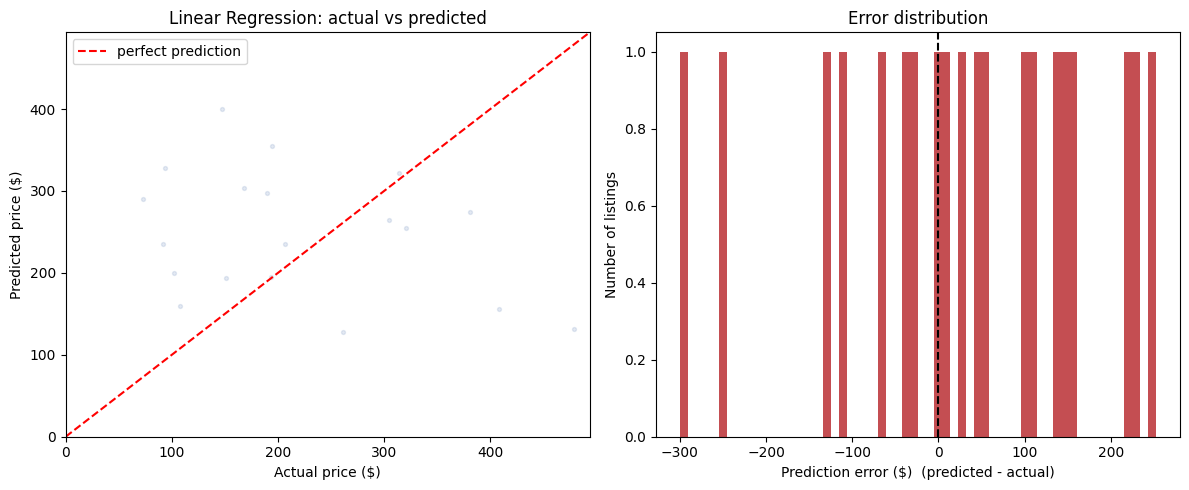

15% of test predictions are within $25 of the real listed price
30% of test predictions are within $50 of the real listed price


In [13]:
lr_model = models["Linear Regression"]
actual = np.exp(y_test)
predicted = np.exp(lr_model.predict(X_test))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: actual vs predicted (zoomed to the 99th percentile for readability)
limit = float(actual.quantile(0.99))
axes[0].scatter(actual, predicted, alpha=0.15, s=8, color="#4C72B0")
axes[0].plot([0, limit], [0, limit], "r--", label="perfect prediction")
axes[0].set_xlim(0, limit); axes[0].set_ylim(0, limit)
axes[0].set_xlabel("Actual price ($)"); axes[0].set_ylabel("Predicted price ($)")
axes[0].set_title("Linear Regression: actual vs predicted"); axes[0].legend()

# Right: how big are the errors? (errors beyond +-$300 are grouped into the two end bars)
errors = (predicted - actual)
axes[1].hist(errors.clip(-300, 300), bins=60, color="#C44E52")
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_xlabel("Prediction error ($)  (predicted - actual)")
axes[1].set_ylabel("Number of listings"); axes[1].set_title("Error distribution")
plt.tight_layout(); plt.show()

within_25 = (np.abs(errors) <= 25).mean() * 100
within_50 = (np.abs(errors) <= 50).mean() * 100
print(f"{within_25:.0f}% of test predictions are within $25 of the real listed price")
print(f"{within_50:.0f}% of test predictions are within $50 of the real listed price")

## 13. Explain the Linear Regression (what drives the price?)

This is the big advantage of Linear Regression: we can read its weights (coefficients).

Because the model predicts **log(price)**, a coefficient `w` means:
*when this feature increases by 1 (or a category is present), the price changes by about* `(e^w − 1) × 100 %`,
*keeping everything else the same.*

Approximate effect of a +1 unit change (all else equal):


,price change (%)
beds,-3.6
bathrooms,-3.2
accommodates,1.2
bedrooms,4.3


Approximate amenity effects (associations, not causal effects):


,price change (%)
Kitchen,-0.3
Air conditioning,-0.3
TV,-0.3
parking,-0.3
Wireless Internet,0.0
Heating,0.0


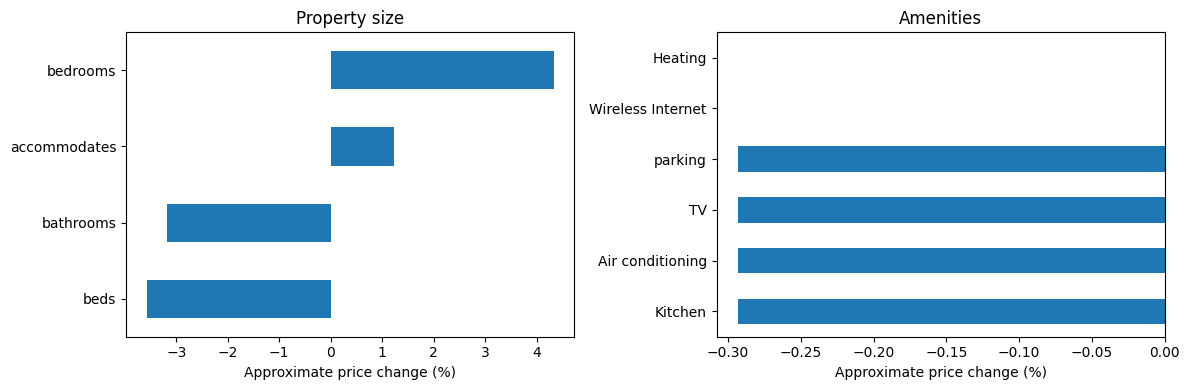

In [14]:
# Inspect the Linear Regression coefficients
lr_model = models["Linear Regression"]
preprocessing = lr_model.named_steps["preprocessor"]
regressor = lr_model.named_steps["regressor"]

feature_names = preprocessing.get_feature_names_out()
coefficients = pd.Series(regressor.coef_, index=feature_names)

def percent_effect(weights):
    return (np.exp(weights) - 1) * 100

size_effect = pd.Series({
    feature: percent_effect(coefficients[f"num__{feature}"])
    for feature in ["accommodates", "bedrooms", "bathrooms", "beds"]
}).sort_values()
print("Approximate effect of a +1 unit change (all else equal):")
display(size_effect.round(1).to_frame("price change (%)"))

amenity_effect = pd.Series({
    AMENITY_MAP[feature]: percent_effect(coefficients[f"num__{feature}"])
    for feature in AMENITY_FEATURES
}).sort_values()
print("Approximate amenity effects (associations, not causal effects):")
display(amenity_effect.round(1).to_frame("price change (%)"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
size_effect.plot(kind="barh", ax=axes[0], title="Property size")
amenity_effect.plot(kind="barh", ax=axes[1], title="Amenities")
for ax in axes:
    ax.set_xlabel("Approximate price change (%)")
plt.tight_layout()
plt.show()


## 14. Predict the price of a new listing

`predict_price()` is the function a website will call after the user submits a form.
It checks the inputs, builds a one-row table in the same format as the training data,
and returns the estimated nightly price in dollars.

We use **Linear Regression** as the final model because it only needs simple form inputs
(city, neighbourhood, room type, guests, ...) and it is explainable.

In [15]:
final_model = models["Linear Regression"]
final_model_name = "Linear Regression"
VALID_CITIES = sorted(df_clean["city"].dropna().astype(str).unique())

def predict_price(
    city, neighbourhood="Unknown", property_type="Apartment",
    room_type="Entire home/apt", bed_type="Real Bed",
    cancellation_policy="moderate", accommodates=2, bathrooms=1.0,
    bedrooms=1, beds=1, cleaning_fee=False, instant_bookable=False,
    amenities=("wifi", "kitchen", "heating")
):
    # Estimate the nightly listed price in US dollars.
    if not 1 <= int(accommodates) <= 16:
        raise ValueError("accommodates must be between 1 and 16")
    if not 0 <= float(bathrooms) <= 8:
        raise ValueError("bathrooms must be between 0 and 8")
    if not 0 <= int(bedrooms) <= 10:
        raise ValueError("bedrooms must be between 0 and 10")
    if not 0 <= int(beds) <= 18:
        raise ValueError("beds must be between 0 and 18")

    aliases = {
        "wifi": "has_wifi", "wireless internet": "has_wifi",
        "kitchen": "has_kitchen", "ac": "has_ac", "air conditioning": "has_ac",
        "heating": "has_heating", "tv": "has_tv", "parking": "has_parking",
    }
    chosen = {str(a).strip().lower() for a in amenities}
    unknown = chosen - set(aliases)
    if unknown:
        raise ValueError(f"Unknown amenities: {sorted(unknown)}")
    selected_features = {aliases[a] for a in chosen}

    row = {
        "city": city, "neighbourhood": neighbourhood or "Unknown",
        "property_type": property_type, "room_type": room_type,
        "bed_type": bed_type, "cancellation_policy": cancellation_policy,
        "accommodates": int(accommodates), "bathrooms": float(bathrooms),
        "bedrooms": int(bedrooms), "beds": int(beds),
        "cleaning_fee": int(bool(cleaning_fee)),
        "instant_bookable": int(bool(instant_bookable)),
    }
    for feature in AMENITY_FEATURES:
        row[feature] = int(feature in selected_features)

    new_listing = pd.DataFrame([row], columns=ALL_FEATURES)
    return float(np.exp(final_model.predict(new_listing)[0]))

# Demo: use an actual listing's known values
sample = df_clean.iloc[0]
sample_amenities = [
    alias for alias, feature in [
        ("wifi", "has_wifi"), ("kitchen", "has_kitchen"), ("ac", "has_ac"),
        ("heating", "has_heating"), ("tv", "has_tv"), ("parking", "has_parking")
    ] if sample[feature] == 1
]
estimate = predict_price(
    city=str(sample["city"]),
    neighbourhood=str(sample["neighbourhood"]),
    property_type=str(sample["property_type"]),
    room_type=str(sample["room_type"]),
    bed_type=str(sample["bed_type"]),
    cancellation_policy=str(sample["cancellation_policy"]),
    accommodates=int(sample["accommodates"]),
    bathrooms=float(sample["bathrooms"]) if pd.notna(sample["bathrooms"]) else 1.0,
    bedrooms=int(sample["bedrooms"]) if pd.notna(sample["bedrooms"]) else 1,
    beds=int(sample["beds"]) if pd.notna(sample["beds"]) else 1,
    cleaning_fee=bool(sample["cleaning_fee"]),
    instant_bookable=bool(sample["instant_bookable"]),
    amenities=sample_amenities
)
print("Demo prediction for one real listing")
print(f"City / room type: {sample['city']} / {sample['room_type']}")
print(f"Actual listed price: ${sample['price']:,.0f}")
print(f"Predicted price:     ${estimate:,.0f}")


Demo prediction for one real listing
City / room type: DC / Shared room
Actual listed price: $108
Predicted price:     $159


## 15. Try it yourself — type your own listing (optional)

Set `RUN_INTERACTIVE = True` and run this cell to enter your own details.
Press **Enter** without typing to accept the default shown in brackets.
This is exactly what the website form will do later.

In [16]:
RUN_INTERACTIVE = False  # Set to True if running in a notebook that supports input()

def ask(question, default, cast=str):
    answer = input(f"{question} [{default}]: ").strip()
    return cast(answer) if answer else default

def interactive_prediction():
    print("Available cities:", VALID_CITIES)
    city = ask("City", VALID_CITIES[0])
    neighbourhood = ask("Neighbourhood", "Unknown")
    room_type = ask("Room type", "Entire home/apt")
    guests = ask("Guests accommodated", 2, int)
    bedrooms = ask("Bedrooms", 1, int)
    bathrooms = ask("Bathrooms", 1.0, float)
    beds = ask("Beds", 1, int)
    amenity_text = ask("Amenities (comma-separated: wifi,kitchen,ac,heating,tv,parking)", "wifi,kitchen")
    amenity_list = [a.strip() for a in amenity_text.split(",") if a.strip()]
    price = predict_price(city, neighbourhood, room_type=room_type, accommodates=guests,
                          bathrooms=bathrooms, bedrooms=bedrooms, beds=beds, amenities=amenity_list)
    print(f"Estimated listed price: ${price:,.0f} per night")
    print(f"Test-set MAE: ${results.loc['Linear Regression', 'MAE ($)']:.0f} per night")

if RUN_INTERACTIVE:
    interactive_prediction()
else:
    print("Interactive demo is off. Set RUN_INTERACTIVE = True to type a listing.")


Interactive demo is off. Set RUN_INTERACTIVE = True to type a listing.


## 16. Save the trained model (for your website)

We save the model **and** the dropdown options a website form needs (cities, neighbourhoods per city,
room types, ...) in one file with `joblib`. Keep the file together with the same scikit-learn version
that trained it, and never load `.joblib` files from people you do not trust.

**Website idea (later):** the browser (HTML/CSS/JS) cannot run a scikit-learn model directly.
The usual design is:

`HTML form → JavaScript fetch() → small Python API (Flask or FastAPI) → loads this .joblib file → returns the price → JavaScript shows it`

If you want, I can build that Flask API and the HTML page for you as the next step.

In [17]:
from pathlib import Path

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / "airbnb_price_model.joblib"

model_bundle = {
    "model": final_model,
    "model_name": final_model_name,
    "all_features": ALL_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "amenity_map": AMENITY_MAP,
    "cities": VALID_CITIES,
    "neighbourhoods_by_city": {
        city: sorted(group["neighbourhood"].astype(str).unique().tolist())
        for city, group in df_clean.groupby("city")
    },
    "property_types": sorted(df_clean["property_type"].dropna().astype(str).unique()),
    "room_types": sorted(df_clean["room_type"].dropna().astype(str).unique()),
    "bed_types": sorted(df_clean["bed_type"].dropna().astype(str).unique()),
    "cancellation_policies": sorted(df_clean["cancellation_policy"].dropna().astype(str).unique()),
    "test_mae_dollars": float(results.loc["Linear Regression", "MAE ($)"]),
    "note": "Predicts historical listed prices from this dataset, not guaranteed current market prices."
}
joblib.dump(model_bundle, MODEL_PATH)
print(f"Model saved to: {MODEL_PATH.resolve()}")

loaded = joblib.load(MODEL_PATH)
test_row = X_test.iloc[[0]]
same = np.isclose(loaded["model"].predict(test_row)[0], final_model.predict(test_row)[0])
print("Reload check passed:", bool(same))


Model saved to: /Users/anishmd/models/airbnb_price_model.joblib
Reload check passed: True


## 17. Conclusion

We built a supervised regression workflow: data loading and cleaning, amenity feature engineering, exploratory analysis, train/test split, a median baseline, Linear Regression, evaluation in dollars, a prediction function, and a saved model.

### Key points for your report / viva
- **Problem type:** supervised regression because the target is numeric.
- **Why log price?** Prices are right-skewed; predictions are converted back to dollars using `np.exp()`.
- **Why a pipeline?** It applies consistent preprocessing and avoids learning imputation/encoding from the test set.
- **One-hot encoding:** converts categories such as city and room type into numeric indicator columns.
- **Baseline:** the median baseline shows whether Linear Regression adds value.
- **Metrics:** MAE and RMSE are in dollars; R² is not an accuracy percentage.
- **Limitations:** predicts historical listed prices, not bookings, occupancy, costs, profit, or guaranteed current market prices.
- **Future work:** tune the model, add seasonality, and deploy through a Flask/FastAPI API.
